# [01] Data Audit and EDA



In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').exists())
sys.path.insert(0, str(ROOT))

from src import config
from src.data import load_raw,clean_data,split_data

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

## [_1_] Load and inspect

In [2]:
df = load_raw()
print('Shape:', df.shape)
df.head()

Shape: (2000, 17)


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [3]:
structure = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(),
    'n_missing': df.isna().sum(),
    'pct_missing': (df.isna().mean() * 100).round(2),
})
structure

,dtype,n_unique,n_missing,pct_missing
Student_ID,str,2000,0,0.00
Age,int64,13,0,0.00
Gender,str,3,0,0.00
Year_of_Study,int64,5,0,0.00
Sleep_Hours,float64,66,62,3.10
Study_Hours_Per_Week,float64,284,0,0.00
GPA,float64,182,38,1.90
Social_Media_Hours,float64,71,58,2.90
Screen_Time_Hours,float64,95,0,0.00
Physical_Activity,str,3,0,0.00


## [_2_] Clean the data

`clean_data` converts numeric columns to numbers, normalizes text values to the documented categories, and leaves missing values as NaN (they will be imputed inside the ML pipeline).

In [4]:
df_clean = clean_data(df)
print('Shape after cleaning:', df_clean.shape)

missing_after = df_clean.isna().sum()
missing_after[missing_after > 0]

Shape after cleaning: (2000, 17)


Sleep_Hours           62
GPA                   38
Social_Media_Hours    58
Financial_Stress      91
Family_Support        54
Attendance_Rate       47
Diet_Quality          69
dtype: int64

In [5]:
numeric_cols = list(config.NUMERIC_RANGES.keys())

ranges = df_clean[numeric_cols].agg(['min', 'max']).T
ranges.columns = ['min_observed', 'max_observed']
ranges['min_expected'] = [config.NUMERIC_RANGES[c][0] for c in ranges.index]
ranges['max_expected'] = [config.NUMERIC_RANGES[c][1] for c in ranges.index]
ranges.round(2)

,min_observed,max_observed,min_expected,max_expected
Age,17.0,29.00,18.0,30.0
Year_of_Study,1.0,5.00,1.0,5.0
Sleep_Hours,3.3,10.00,3.5,9.5
Study_Hours_Per_Week,2.4,38.30,5.0,55.0
GPA,1.5,3.66,1.5,4.0
Social_Media_Hours,2.1,10.00,0.5,10.0
Screen_Time_Hours,3.3,14.00,1.0,14.0
Financial_Stress,1.4,10.00,1.0,10.0
Family_Support,1.7,9.90,1.0,10.0
Attendance_Rate,54.4,100.00,30.0,100.0


## [_3_] Target distribution

The classes should be roughly balanced (~33% each).

Mental_Health_Risk
Low       660
Medium    660
High      680
Name: count, dtype: int64

Ratio max/min: 1.03


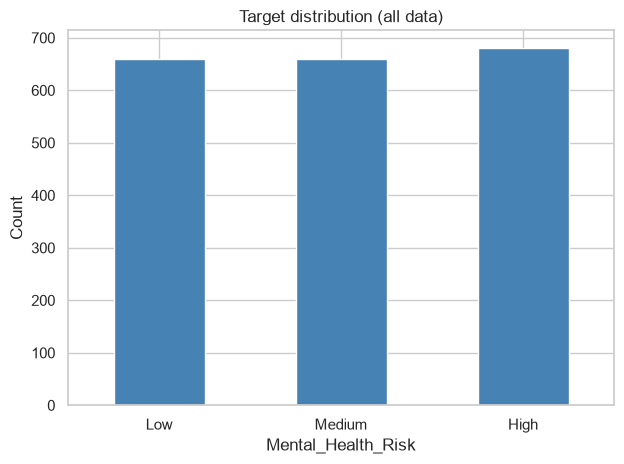

In [6]:
target_counts = df_clean[config.TARGET_COL].value_counts().reindex(config.TARGET_ORDER)
print(target_counts)
print(f'\nRatio max/min: {target_counts.max() / target_counts.min():.2f}')

target_counts.plot(kind='bar', color='steelblue')
plt.title('Target distribution (all data)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(config.FIGURES / '01_target_distribution.png', dpi=120)
plt.show()

## [_4_] Train/test split

Stratified 80/20 split. The test set is saved and **not used in the rest of this notebook**.

In [ ]:
train, test, split_info = split_data(df_clean)
print(json.dumps(split_info, indent=2))

# Everything below uses the training data
df = train

{
  "n_dropped_missing_target": 0,
  "n_dropped_duplicates": 0,
  "n_train": 1600,
  "n_test": 400,
  "train_missing_values": {
    "Student_ID": 0,
    "Age": 0,
    "Gender": 0,
    "Year_of_Study": 0,
    "Sleep_Hours": 54,
    "Study_Hours_Per_Week": 0,
    "GPA": 36,
    "Social_Media_Hours": 48,
    "Screen_Time_Hours": 0,
    "Physical_Activity": 0,
    "Financial_Stress": 76,
    "Family_Support": 36,
    "Attendance_Rate": 39,
    "Part_Time_Job": 0,
    "Diet_Quality": 55,
    "Previous_Mental_Health_History": 0,
    "Mental_Health_Risk": 0
  },
  "test_missing_values": {
    "Student_ID": 0,
    "Age": 0,
    "Gender": 0,
    "Year_of_Study": 0,
    "Sleep_Hours": 8,
    "Study_Hours_Per_Week": 0,
    "GPA": 2,
    "Social_Media_Hours": 10,
    "Screen_Time_Hours": 0,
    "Physical_Activity": 0,
    "Financial_Stress": 15,
    "Family_Support": 18,
    "Attendance_Rate": 8,
    "Part_Time_Job": 0,
    "Diet_Quality": 14,
    "Previous_Mental_Health_History": 0,
    "Mental_H

## [_5_] Descriptive statistics (train only)

In [8]:
df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1600.0,21.14,2.13,17.0,20.00,21.00,23.0,28.00
Year_of_Study,1600.0,2.62,1.31,1.0,1.00,2.00,4.0,5.00
Sleep_Hours,1546.0,6.75,1.12,3.6,6.00,6.70,7.5,10.00
Study_Hours_Per_Week,1600.0,19.98,5.77,2.4,16.00,19.80,24.0,38.30
GPA,1564.0,2.56,0.35,1.5,2.32,2.56,2.8,3.66
Social_Media_Hours,1552.0,6.04,1.13,2.1,5.30,6.00,6.8,10.00
Screen_Time_Hours,1600.0,8.58,1.66,3.3,7.40,8.50,9.7,14.00
Financial_Stress,1524.0,5.96,1.91,1.4,4.50,6.10,7.4,10.00
Family_Support,1564.0,6.52,1.84,1.7,5.20,6.70,8.0,9.90
Attendance_Rate,1561.0,85.05,7.28,54.4,80.20,85.10,90.1,100.00


In [9]:
cat_cols = list(config.CATEGORICAL_VALUES.keys())
df[cat_cols].describe().T

,count,unique,top,freq
Gender,1600,3,Female,779
Physical_Activity,1600,3,Moderate,742
Diet_Quality,1545,3,Average,687
Part_Time_Job,1600,2,No,1029
Previous_Mental_Health_History,1600,2,No,1140


## [_6_] Distributions

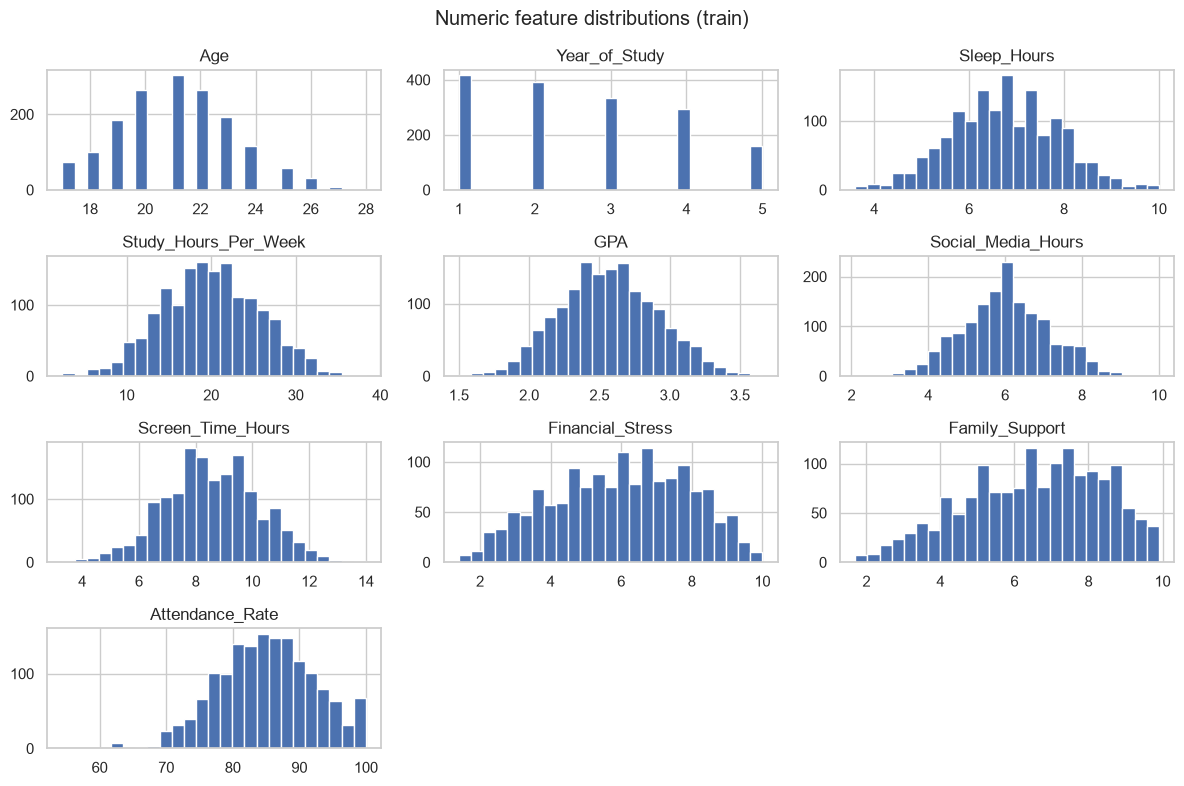

In [10]:
df[numeric_cols].hist(figsize=(12, 8), bins=25)
plt.suptitle('Numeric feature distributions (train)')
plt.tight_layout()
plt.savefig(config.FIGURES / '01_histograms.png', dpi=120)
plt.show()

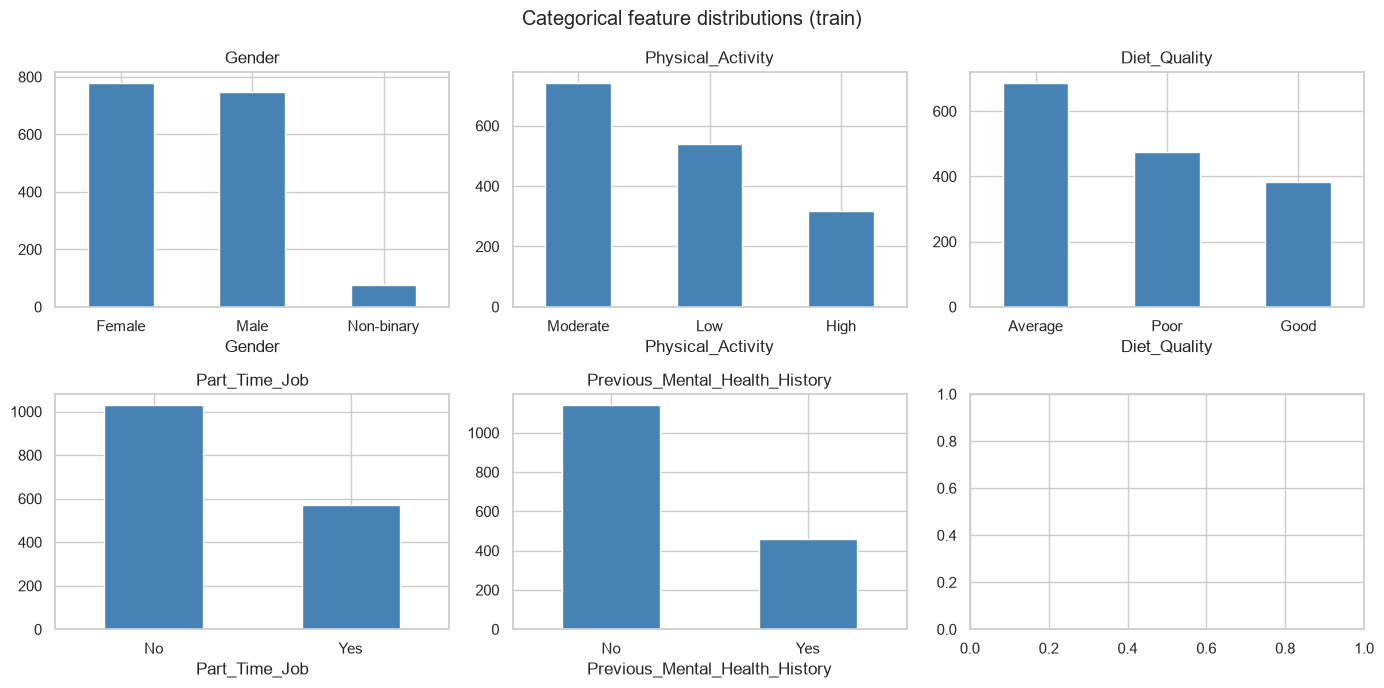

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    df[col].value_counts().plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=0)
plt.suptitle('Categorical feature distributions (train)')
plt.tight_layout()
plt.savefig(config.FIGURES / '01_categorical_distributions.png', dpi=120)
plt.show()

## [_8_] Outliers (IQR method)

Count values outside [Q1 - 1.5·IQR, Q3 + 1.5·IQR].

In [12]:
outlier_rows = []
for col in numeric_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < low) | (s > high)).sum())
    outlier_rows.append({
        'column': col,
        'low_bound': round(low, 2),
        'high_bound': round(high, 2),
        'n_outliers': n_out,
        'pct_outliers': round(100 * n_out / len(s), 2),
    })

pd.DataFrame(outlier_rows).set_index('column')

,low_bound,high_bound,n_outliers,pct_outliers
column,,,,
Age,15.50,27.50,2,0.12
Year_of_Study,-3.50,8.50,0,0.00
Sleep_Hours,3.75,9.75,9,0.58
Study_Hours_Per_Week,4.00,36.00,7,0.44
GPA,1.60,3.52,5,0.32
Social_Media_Hours,3.05,9.05,10,0.64
Screen_Time_Hours,3.95,13.15,7,0.44
Financial_Stress,0.15,11.75,0,0.00
Family_Support,1.00,12.20,0,0.00


In [14]:
mask = pd.Series(False, index=df.index)
for col in numeric_cols:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    mask |= (df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)
print(mask.sum(), "rows with at least one outlier")

46 rows with at least one outlier


C:\Users\hamza\AppData\Local\Temp\ipykernel_19180\1380406658.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False)
C:\Users\hamza\AppData\Local\Temp\ipykernel_19180\1380406658.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False)
C:\Users\hamza\AppData\Local\Temp\ipykernel_19180\1380406658.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False)
C:\Users\hamza\AppData\Local\Temp\ipykernel_19180\1380406658.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical'

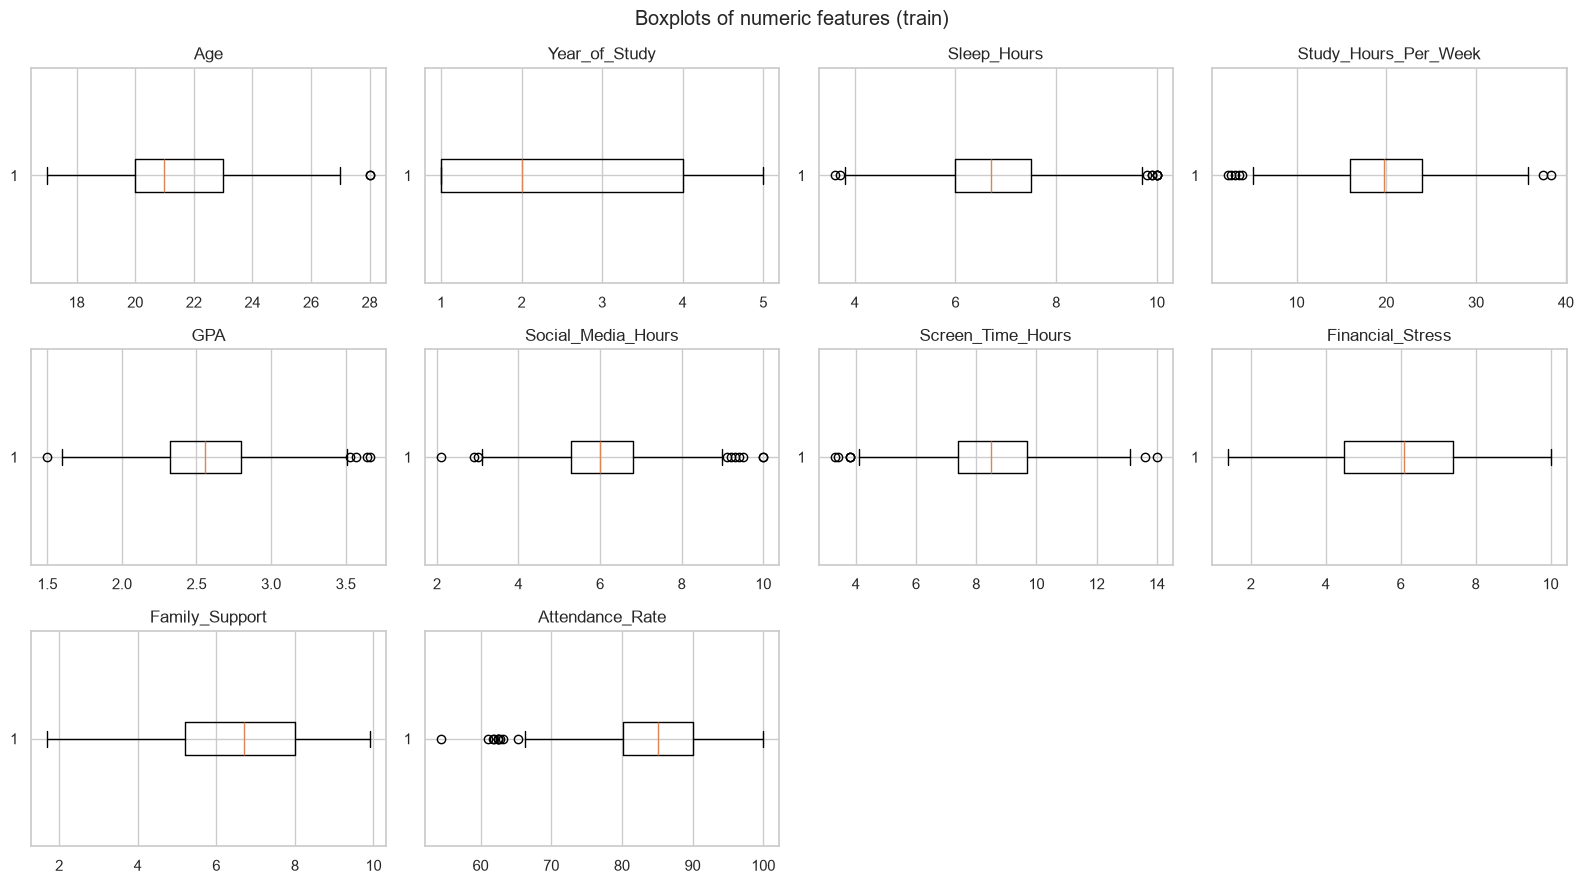

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(col)
for ax in axes.ravel()[len(numeric_cols):]:
    ax.axis('off')
plt.suptitle('Boxplots of numeric features (train)')
plt.tight_layout()
plt.savefig(config.FIGURES / '01_boxplots.png', dpi=120)
plt.show()

## [_8_] Features vs target

How do numeric features look per risk class? And how are classes distributed across categorical values?

In [15]:
means = df.groupby(config.TARGET_COL)[numeric_cols].mean().reindex(config.TARGET_ORDER)
means.round(2).T

Mental_Health_Risk,Low,Medium,High
Age,21.10,21.18,21.12
Year_of_Study,2.89,2.63,2.35
Sleep_Hours,7.51,6.74,6.01
Study_Hours_Per_Week,21.77,19.96,18.25
GPA,2.72,2.55,2.42
Social_Media_Hours,5.77,5.94,6.38
Screen_Time_Hours,8.26,8.44,9.02
Financial_Stress,5.24,5.93,6.68
Family_Support,7.05,6.58,5.97
Attendance_Rate,86.17,85.28,83.73


In [16]:
for col in cat_cols:
    print(f'\n--- {col} ---')
    ct = pd.crosstab(df[col], df[config.TARGET_COL], normalize='index')
    ct = ct.reindex(columns=config.TARGET_ORDER)
    print(ct.round(3))


--- Gender ---
Mental_Health_Risk    Low  Medium   High
Gender                                  
Female              0.330   0.320  0.350
Male                0.323   0.347  0.330
Non-binary          0.400   0.267  0.333

--- Physical_Activity ---
Mental_Health_Risk    Low  Medium   High
Physical_Activity                       
High                0.495   0.301  0.204
Low                 0.239   0.319  0.442
Moderate            0.325   0.350  0.325

--- Diet_Quality ---
Mental_Health_Risk    Low  Medium   High
Diet_Quality                            
Average             0.335   0.332  0.333
Good                0.414   0.317  0.270
Poor                0.254   0.338  0.408

--- Part_Time_Job ---
Mental_Health_Risk    Low  Medium   High
Part_Time_Job                           
No                  0.366   0.334  0.299
Yes                 0.264   0.322  0.413

--- Previous_Mental_Health_History ---
Mental_Health_Risk                Low  Medium   High
Previous_Mental_Health_History          

## [_9_] Correlations between numeric features

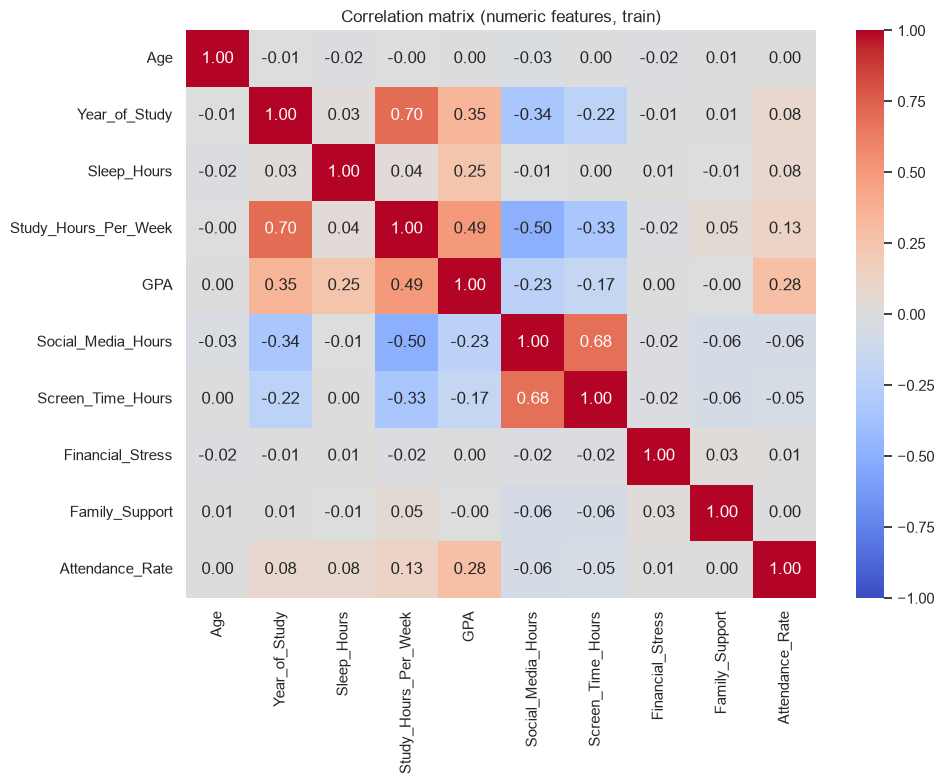

In [17]:
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix (numeric features, train)')
plt.tight_layout()
plt.savefig(config.FIGURES / '01_correlation.png', dpi=120)
plt.show()

## [_10_] Are missing values linked to the target class?

If missing values are more common in one risk class, adding a "was-missing" indicator could help.

In [18]:
rows = []
for col in df.columns:
    if col in (config.TARGET_COL, config.ID_COL):
        continue
    if df[col].isna().sum() == 0:
        continue
    is_missing = df[col].isna()
    rows.append({
        'column': col,
        'n_missing': int(is_missing.sum()),
        'P(High | missing)': round((df.loc[is_missing, config.TARGET_COL] == 'High').mean(), 3),
        'P(High | present)': round((df.loc[~is_missing, config.TARGET_COL] == 'High').mean(), 3),
    })

pd.DataFrame(rows)

,column,n_missing,P(High | missing),P(High | present)
0,Sleep_Hours,54,0.389,0.338
1,GPA,36,0.333,0.340
2,Social_Media_Hours,48,0.312,0.341
3,Financial_Stress,76,0.211,0.346
4,Family_Support,36,0.333,0.340
5,Attendance_Rate,39,0.333,0.340
6,Diet_Quality,55,0.327,0.340


Missing values are below about 5% in each column. I tested whether missingness relates to the target and found no meaningful link, except a borderline signal in Financial_Stress that does not survive multiple-testing correction. I therefore used simple train-fitted imputation and tested a missing indicator for Financial_Stress.